# Fase II-bis — Caso publicado: red de canales de Chaudhry (Ejemplo 6-3)
## Trabajo 01 · Estructura N.º 8 · Confluencia o bifurcación de canales

**Curso:** Flujo en superficie libre — UNSCH, Unidad de Posgrado

**Objetivo.** Verificar el resolvedor de Newton–Raphson propio sobre un **caso numérico publicado** cuyas ecuaciones son las de la Formulación II: nivel/energía común en cada unión, continuidad, y energía entre secciones con fricción de Manning. La fuente es Chaudhry (2008), *Open-Channel Flow*, 2.ª ed., §6-8, Ejemplo 6-3 (Tablas 6-3 y 6-4, Fig. 6-13), que resuelve una red de 8 canales con tres uniones de ramificación o confluencia.

**Qué se verifica y qué no.** El libro verifica *su* código contra Runge–Kutta; aquí se verifica *el nuestro* contra el libro. Como se verá, la tabla impresa cumple nuestras ecuaciones a nivel de redondeo, pero **los caudales del libro no son identificables a partir de los calados impresos** (la red es casi horizontal y la fricción es muy pequeña frente a la pendiente). Por eso el criterio principal es el **residual de las ecuaciones evaluado con los datos publicados**, no la coincidencia de caudales. Esta limitación se documenta en la sección 9.

| Prueba | Naturaleza | Criterio |
|---|---|---|
| P1 | Caso publicado | Los valores impresos cumplen nuestras ecuaciones dentro del redondeo |
| P2 | Caso publicado | Calados calculados frente a la Tabla 6-4 (entradas sin errata evidente) |
| P3 | Método independiente | Perfil por Runge–Kutta de 4.º orden por canal, como hace el libro |
| P4 | Propiedades | Jacobiano analítico vs numérico, continuidad, raíz única desde 40 arranques, orden de convergencia |

## 1. Librerías y versiones

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

print('Python     :', sys.version.split()[0])
print('NumPy      :', np.__version__)
print('pandas     :', pd.__version__)
print('matplotlib :', matplotlib.__version__)

Python     : 3.13.16
NumPy      : 2.5.3
pandas     : 3.0.5
matplotlib : 3.11.2


## 2. Datos del ejemplo (transcritos del libro)

Los datos viven en `datos_ejemplo63.json`, separados del código. Se transcribe **la Tabla 6-3** (geometría) y **la Tabla 6-4** (resultado publicado).

**Topología (Fig. 6-13).** Entra Q = 250 m³/s por el nodo A. Canal 1: A→B; canal 2: A→D; canal 3: B→E; canal 4: B→C; canal 5: C→E; canal 6: D→C; canal 7: E→F; canal 8: D→F. Sección trapezoidal con talud 1.5H:1V en todos, k = 0 en las uniones, α = 1, calado de 5 m en F, pendiente de fondo 0.0005 en todos.

**Cotas de fondo.** El enunciado no da cotas, pero con pendiente 0.0005 y longitudes de la tabla se deduce una cota consistente en todos los nodos (F = 0, E = 0.05, D = 0.15, C = 0.10, B = 0.15, A = 0.25 m), de modo que cualquier camino entre dos nodos da la misma cota. Eso permite igualar niveles de agua en las uniones igualando calados.

### Errores de imprenta evidentes en la Tabla 6-4

Detecté estas inconsistencias **antes de ejecutar nuestro resolvedor**, solo por coherencia interna de la tabla, y las excluyo de las comparaciones:

| Dato impreso | Problema | Evidencia interna |
|---|---|---|
| Q₃ = 55.003 | No cierra el nodo B ni el E | B: 95.748 − 40.655 = 55.093; con 55.093 cierra E: 55.093 + 52.669 = 107.762 |
| Canal 4, secciones 3 y 4: 4.677 y 4.800 | Rompen la tendencia monótona | El canal 6 desemboca en el mismo nodo con 4.877 y 4.889 |
| Canal 7, secciones 1 a 3 | 4.051 es incompatible con el nodo E (≈ 4.951); 4.986 y 4.979 no son monótonos | Nodo E y tendencia hacia 5.000 |
| Canal 8, secciones 1 y 2: 4.352 y 4.860 | 4.352 no coincide con el nodo D (≈ 4.852); 4.860 rompe la tendencia | Nodo D y tendencia hacia 5.000 |

Se usa Q₃ = 55.093 (es la única corrección que reemplaza un valor); de las demás entradas simplemente se prescinde.

In [2]:
datos = {
    "fuente": "Chaudhry, M. H. (2008). Open-Channel Flow, 2nd ed. Springer. Ejemplo 6-3, Tablas 6-3 y 6-4, Fig. 6-13",
    "talud": 1.5, "Q_total": 250.0, "y_F": 5.0, "g": 9.81, "k_union": 0.0,
    "canales": {   # L, b, dx (separacion entre secciones) [m], n de Manning, So
        "1": {"aguas_arriba": "A", "aguas_abajo": "B", "L": 200, "b": 30, "dx": 50, "n": 0.013, "So": 0.0005},
        "2": {"aguas_arriba": "A", "aguas_abajo": "D", "L": 200, "b": 40, "dx": 50, "n": 0.013, "So": 0.0005},
        "3": {"aguas_arriba": "B", "aguas_abajo": "E", "L": 200, "b": 20, "dx": 50, "n": 0.012, "So": 0.0005},
        "4": {"aguas_arriba": "B", "aguas_abajo": "C", "L": 100, "b": 20, "dx": 25, "n": 0.014, "So": 0.0005},
        "5": {"aguas_arriba": "C", "aguas_abajo": "E", "L": 100, "b": 20, "dx": 25, "n": 0.013, "So": 0.0005},
        "6": {"aguas_arriba": "D", "aguas_abajo": "C", "L": 100, "b": 25, "dx": 25, "n": 0.013, "So": 0.0005},
        "7": {"aguas_arriba": "E", "aguas_abajo": "F", "L": 100, "b": 30, "dx": 25, "n": 0.014, "So": 0.0005},
        "8": {"aguas_arriba": "D", "aguas_abajo": "F", "L": 300, "b": 50, "dx": 75, "n": 0.014, "So": 0.0005}},
    # Tabla 6-4 tal como esta impresa (Q en m3/s; calados en m, de aguas arriba a aguas abajo)
    "publicado_Q": {"1": 95.748, "2": 154.252, "3": 55.003, "4": 40.655, "5": 52.669, "6": 12.014, "7": 107.762, "8": 142.238},
    "publicado_y": {"1": [4.754, 4.779, 4.803, 4.828, 4.853], "2": [4.754, 4.779, 4.803, 4.828, 4.852],
                    "3": [4.853, 4.877, 4.902, 4.927, 4.951], "4": [4.853, 4.865, 4.677, 4.800, 4.902],
                    "5": [4.902, 4.914, 4.927, 4.939, 4.952], "6": [4.852, 4.864, 4.877, 4.889, 4.902],
                    "7": [4.051, 4.986, 4.979, 4.988, 5.000], "8": [4.352, 4.860, 4.926, 4.963, 5.000]},
    # entradas con errata evidente (canal, indice de seccion 0..4), segun la tabla de arriba
    "excluidas": [["4", 2], ["4", 3], ["7", 0], ["7", 1], ["7", 2], ["8", 0], ["8", 1]],
    "Q3_corregido": 55.093
}
with open("datos_ejemplo63.json", "w", encoding="utf-8") as f:
    json.dump(datos, f, indent=2, ensure_ascii=False)
with open("datos_ejemplo63.json", encoding="utf-8") as f:
    D = json.load(f)

TALUD, G, Q_TOTAL, Y_F = D["talud"], D["g"], D["Q_total"], D["y_F"]
CANALES = {int(k): (v["aguas_arriba"], v["aguas_abajo"], v["L"], v["b"], v["dx"], v["n"], v["So"])
           for k, v in D["canales"].items()}
NODOS_CONT = {"A": ([], [1, 2]), "B": ([1], [3, 4]), "C": ([4, 6], [5]),
              "D": ([2], [6, 8]), "E": ([3, 5], [7])}   # (canales que entran, canales que salen)

# Comprobacion de las cotas de fondo deducidas (cualquier camino debe dar la misma cota)
z = {"F": 0.0}
z["E"] = z["F"] + 0.0005*100; z["D"] = z["F"] + 0.0005*300
z["B"] = z["E"] + 0.0005*200; z["C"] = z["E"] + 0.0005*100; z["A"] = z["D"] + 0.0005*200
chequeos = {1: z["A"] - z["B"], 2: z["A"] - z["D"], 4: z["B"] - z["C"], 6: z["D"] - z["C"]}
esperado = {i: CANALES[i][2]*0.0005 for i in chequeos}
print("Cotas de fondo [m]:", {k: round(v, 3) for k, v in z.items()})
print("Cotas consistentes con las longitudes:", all(abs(chequeos[i] - esperado[i]) < 1e-12 for i in chequeos))

Cotas de fondo [m]: {'F': 0.0, 'E': 0.05, 'D': 0.15, 'B': 0.15, 'C': 0.1, 'A': 0.25}
Cotas consistentes con las longitudes: True


## 3. Ecuaciones y ensamblaje del sistema

**Incógnitas.** El calado en cada sección de cada canal (5 por canal, 40 en total) y un caudal por canal (8): **48 incógnitas**, como en Chaudhry §6-8.

**Ecuaciones (48).**

1. *Energía entre secciones consecutivas* (32), con fricción promediada entre extremos y Manning en SI:

$$F=y_{j+1}-y_j-S_o\,\Delta x+\frac{Q^2}{2g}\Big(\frac1{A_{j+1}^2}-\frac1{A_j^2}\Big)+\frac{\Delta x}{2}\big(S_{f,j}+S_{f,j+1}\big)=0,\qquad S_f=\frac{n^2Q^2P^{4/3}}{A^{10/3}}$$

2. *Continuidad* en los nodos A, B, C, D y E (5). El nodo F es redundante porque la suma de los demás lo implica.
3. *Igualdad de nivel* en las uniones (11): en el caso del libro la tabla muestra calados iguales en cada nodo, así que se desprecian la carga de velocidad y la pérdida local (la forma entre paréntesis de la Ec. 6-67).
4. *Condición aguas abajo* (2): y = 5 m al final de los canales 7 y 8.

**Jacobiano analítico**, derivado a mano para este ensamblaje (compatible con las derivadas de Chaudhry, Ec. 6-65). Se verifica contra diferencias centrales en la prueba P4. La continuidad se divide por $Q_0=250$ para que sus residuales sean comparables con los de energía, que están en metros.

El código reutiliza **sin cambios** el `newton_amortiguado` de las fases anteriores.

In [3]:
def newton_amortiguado(F, J, x0, tol=1e-12, max_iter=60, paso_min=1e-6):
    """Newton-Raphson con retroceso. Devuelve (x, tabla de iteraciones, convergio)."""
    x = np.array(x0, dtype=float)
    if F(x) is None:
        raise ValueError("El valor inicial es fisicamente inadmisible.")
    filas, lam_paso = [], np.nan
    for k in range(max_iter + 1):
        Fx = F(x)
        normF = np.max(np.abs(Fx))
        filas.append({"Iteración": k, **{f"x{j+1}": x[j] for j in range(len(x))},
                      "‖F‖∞": normF, "λk (paso)": lam_paso})
        if normF < tol:
            return x, pd.DataFrame(filas), True
        dx = np.linalg.solve(J(x), -Fx)
        lam_paso = 1.0
        while lam_paso >= paso_min:
            x_nuevo = x + lam_paso*dx
            F_nuevo = F(x_nuevo)
            if F_nuevo is not None and np.max(np.abs(F_nuevo)) < (1 - 1e-4*lam_paso)*normF:
                break
            lam_paso /= 2
        else:
            return x, pd.DataFrame(filas), False
        x = x_nuevo
    return x, pd.DataFrame(filas), False

In [4]:
def geometria(y, b):
    A = b*y + TALUD*y**2
    P = b + 2*y*np.sqrt(1 + TALUD**2)
    B = b + 2*TALUD*y
    return A, P, B


def friccion(y, Q, b, n):
    """Sf de Manning y sus derivadas respecto de y y Q."""
    A, P, B = geometria(y, b)
    S = n**2*Q**2*P**(4/3)/A**(10/3)
    return S, S*((4/3)*2*np.sqrt(1 + TALUD**2)/P - (10/3)*B/A), 2*S/Q


def carga(y, Q, b, c):
    """y + c V^2/2g y sus derivadas respecto de y y Q (c=0 desprecia carga de velocidad)."""
    A, P, B = geometria(y, b)
    return y + c*Q**2/(2*G*A**2), 1 - c*Q**2*B/(G*A**3), c*Q/(G*A**2)


class Red:
    """Ensamblaje del sistema F(X)=0: calados en cada seccion y un caudal por canal."""
    def __init__(self, canales=CANALES, k=0.0, carga_vel=False):
        self.can, self.k, self.cv = canales, k, carga_vel
        self.ids = sorted(canales)
        self.N = {i: int(round(canales[i][2]/canales[i][4])) for i in self.ids}
        self.off, pos = {}, 0
        for i in self.ids:
            self.off[i] = pos
            pos += self.N[i] + 1
        self.iQ = {i: pos + j for j, i in enumerate(self.ids)}
        self.n = pos + len(self.ids)
        # extremos de cada canal en el vector X
        self.extremo = {i: (self.off[i], self.off[i] + self.N[i]) for i in self.ids}

    def _nodo_ecs(self):
        """Lista de ecuaciones de energia en nodos: (canal ref, extremo ref, canal, extremo)."""
        ecs = []
        for nodo in "ABCDE":
            miembros = [(i, 1) for i in self.ids if self.can[i][1] == nodo] + \
                       [(i, 0) for i in self.ids if self.can[i][0] == nodo]
            ref = miembros[0]
            ecs += [(ref, m) for m in miembros[1:]]
        return ecs

    def _c(self, extremo):          # extremo 1 = fin de canal (entra), 0 = inicio (sale)
        return (0.0 if not self.cv else (1.0 if extremo == 1 else 1.0 + self.k))

    def F_J(self, X, jac=True):
        n = self.n
        F, J = [], []
        def fila():
            return np.zeros(n)
        # 1) energia entre secciones consecutivas de cada canal
        for i in self.ids:
            _, _, L, b, dx, nm, So = self.can[i]
            Q = X[self.iQ[i]]
            for j in range(self.N[i]):
                a, c_ = self.off[i] + j, self.off[i] + j + 1
                y0, y1 = X[a], X[c_]
                if y0 <= 0 or y1 <= 0 or Q <= 0:
                    return (None, None) if jac else None
                A0, _, B0 = geometria(y0, b); A1, _, B1 = geometria(y1, b)
                S0, dS0y, dS0Q = friccion(y0, Q, b, nm)
                S1, dS1y, dS1Q = friccion(y1, Q, b, nm)
                F.append(y1 - y0 - So*dx + Q**2/(2*G)*(1/A1**2 - 1/A0**2) + 0.5*dx*(S0 + S1))
                if jac:
                    r = fila()
                    r[a] = -1 + Q**2*B0/(G*A0**3) + 0.5*dx*dS0y
                    r[c_] = 1 - Q**2*B1/(G*A1**3) + 0.5*dx*dS1y
                    r[self.iQ[i]] = Q/G*(1/A1**2 - 1/A0**2) + 0.5*dx*(dS0Q + dS1Q)
                    J.append(r)
        # 2) continuidad en los nodos A..E (el nodo F es redundante)
        for nodo, (ent, sal) in NODOS_CONT.items():
            F.append((sum(X[self.iQ[i]] for i in sal) - sum(X[self.iQ[i]] for i in ent)
                      - (Q_TOTAL if nodo == "A" else 0.0))/Q_TOTAL)
            if jac:
                r = fila()
                for i in sal: r[self.iQ[i]] += 1/Q_TOTAL
                for i in ent: r[self.iQ[i]] -= 1/Q_TOTAL
                J.append(r)
        # 3) igualdad de energia en cada nodo de union (con z continua: cotas de fondo)
        for (i1, e1), (i2, e2) in self._nodo_ecs():
            h1, dy1, dQ1 = self._head(X, i1, e1)
            h2, dy2, dQ2 = self._head(X, i2, e2)
            F.append(h1 - h2)
            if jac:
                r = fila()
                r[self.extremo[i1][e1]] += dy1; r[self.iQ[i1]] += dQ1
                r[self.extremo[i2][e2]] -= dy2; r[self.iQ[i2]] -= dQ2
                J.append(r)
        # 4) condicion aguas abajo: y = Y_F en los extremos finales de los canales 7 y 8
        for i in (7, 8):
            F.append(X[self.extremo[i][1]] - Y_F)
            if jac:
                r = fila(); r[self.extremo[i][1]] = 1.0; J.append(r)
        F = np.array(F)
        return (F, np.array(J)) if jac else F

    def _head(self, X, i, e):
        y = X[self.extremo[i][e]]; Q = X[self.iQ[i]]
        return carga(y, Q, self.can[i][3], self._c(e))

    def F(self, X):
        return self.F_J(X, jac=False)

    def J(self, X):
        return self.F_J(X)[1]

## 4. Resolución con el arranque del libro

Chaudhry arranca con todos los calados iguales a 5 m y caudales aleatorios que **no** cumplen continuidad. Se repite eso con semilla fija. Tolerancia $\|F\|_\infty<10^{-12}$ (el libro usó 0.0005 en las correcciones).

In [5]:
SEMILLA = 20261017
red = Red()

def arranque(semilla):
    rng = np.random.default_rng(semilla)
    X0 = np.zeros(red.n)
    for i in red.ids:
        X0[red.off[i]:red.off[i] + red.N[i] + 1] = 5.0            # calados iniciales = 5 m
        X0[red.iQ[i]] = rng.uniform(20.0, 150.0)                   # caudales arbitrarios
    return X0

X0 = arranque(SEMILLA)
X, tabla, ok = newton_amortiguado(red.F, red.J, X0, tol=1e-12)
print(f"Convergió: {ok}   iteraciones: {len(tabla)-1}   ‖F‖∞ final = {tabla['‖F‖∞'].iloc[-1]:.2e}   incógnitas: {red.n}")
display(tabla[["Iteración", "‖F‖∞", "λk (paso)"]])

Convergió: True   iteraciones: 5   ‖F‖∞ final = 6.94e-16   incógnitas: 48


,Iteración,‖F‖∞,λk (paso)
0,0,6.732859e-01,NaN
1,1,6.514796e-04,1.0
2,2,2.555343e-05,1.0
3,3,1.113663e-07,1.0
4,4,2.430496e-12,1.0
5,5,6.938352e-16,1.0


## 5. Resultado frente a la Tabla 6-4

In [6]:
Q_pub = {int(k): v for k, v in D["publicado_Q"].items()}
Q_pub[3] = D["Q3_corregido"]
Y_pub = {int(k): np.array(v) for k, v in D["publicado_y"].items()}
excl = {(int(c), j) for c, j in D["excluidas"]}

filas = []
for i in red.ids:
    filas.append({"Canal": i, "Q calculado [m³/s]": X[red.iQ[i]], "Q publicado [m³/s]": Q_pub[i],
                  "ΔQ": X[red.iQ[i]] - Q_pub[i], "ΔQ [%]": 100*(X[red.iQ[i]] - Q_pub[i])/Q_pub[i]})
tQ = pd.DataFrame(filas)
display(tQ.style.format({"Q calculado [m³/s]": "{:.3f}", "Q publicado [m³/s]": "{:.3f}", "ΔQ": "{:+.3f}", "ΔQ [%]": "{:+.1f}"}).hide(axis="index"))

filas = []
for i in red.ids:
    yc = X[red.off[i]:red.off[i] + red.N[i] + 1]
    for j in range(red.N[i] + 1):
        filas.append({"Canal": i, "Sección": j + 1, "x [m]": j*CANALES[i][4], "y calculado [m]": yc[j],
                      "y publicado [m]": Y_pub[i][j], "excluida": (i, j) in excl,
                      "Δy [mm]": 1000*(yc[j] - Y_pub[i][j])})
tY = pd.DataFrame(filas)
dy_incl = tY.loc[~tY["excluida"], "Δy [mm]"]
print(f"Calados comparados: {len(dy_incl)} de {len(tY)} (se excluyen {len(excl)} por errata evidente)")
print(f"Δy (calculado − publicado): mínimo {dy_incl.min():+.2f} mm, máximo {dy_incl.max():+.2f} mm, media {dy_incl.mean():+.2f} mm")
display(tY[tY["Canal"].isin([1, 8])].style.format({"y calculado [m]": "{:.4f}", "y publicado [m]": "{:.3f}", "Δy [mm]": "{:+.2f}"}).hide(axis="index"))

Canal,Q calculado [m³/s],Q publicado [m³/s],ΔQ,ΔQ [%]
1,102.273,95.748,+6.525,+6.8
2,147.727,154.252,-6.525,-4.2
3,60.743,55.093,+5.650,+10.3
4,41.530,40.655,+0.875,+2.2
5,57.542,52.669,+4.873,+9.3
6,16.012,12.014,+3.998,+33.3
7,118.285,107.762,+10.523,+9.8
8,131.715,142.238,-10.523,-7.4


Calados comparados: 33 de 40 (se excluyen 7 por errata evidente)
Δy (calculado − publicado): mínimo -1.91 mm, máximo +0.00 mm, media -0.95 mm


Canal,Sección,x [m],y calculado [m],y publicado [m],excluida,Δy [mm]
1,1,0,4.7524,4.754,False,-1.58
1,2,50,4.7771,4.779,False,-1.86
1,3,100,4.8019,4.803,False,-1.12
1,4,150,4.8266,4.828,False,-1.39
1,5,200,4.8514,4.853,False,-1.65
8,1,0,4.8511,4.352,True,+499.15
8,2,75,4.8883,4.860,True,+28.35
8,3,150,4.9256,4.926,False,-0.44
8,4,225,4.9628,4.963,False,-0.22
8,5,300,5.0000,5.000,False,+0.00


**Lectura.** Los calados coinciden con el libro dentro de unos 2 mm, con un desfase sistemático. Los **caudales, en cambio, no coinciden**: hay diferencias de varios m³/s, de hasta decenas de por ciento en el canal 6, que lleva poco caudal. Antes de decidir qué significa, hay que saber si el libro y nuestro código resuelven el mismo sistema. Eso lo responde la prueba P1.

## 6. Pruebas de verificación

### P1 — Los valores impresos en el libro, ¿cumplen nuestras ecuaciones?

Se sustituye la Tabla 6-4 (con Q₃ corregido) en nuestro $F(X)$ y se mira cuánto valen los residuales. Solo entran las ecuaciones cuyas variables **no** están entre las excluidas.

**Tolerancia fijada por redondeo:** los calados están impresos a 1 mm, o sea ±0.5 mm. Cada ecuación de energía y de nivel combina dos calados, así que el residual esperado por redondeo es de hasta 1 mm; se adopta **1.5 mm**. Este valor se fijó por el redondeo de la tabla, no ajustándolo a un resultado.

In [7]:
Xpub = np.zeros(red.n)
for i in red.ids:
    Xpub[red.off[i]:red.off[i] + red.N[i] + 1] = Y_pub[i]
    Xpub[red.iQ[i]] = Q_pub[i]
excluidas_idx = {red.off[i] + j for (i, j) in excl}

Fp, Jp = red.F_J(Xpub)
usa_excl = np.array([any(abs(Jp[r, c]) > 0 for c in excluidas_idx) for r in range(len(Fp))])
res_pub = np.abs(Fp[~usa_excl])
# los residuales de continuidad estan divididos por Q_total: se devuelven a m3/s
n_en = sum(red.N.values())
idx_cont = np.arange(n_en, n_en + 5)
res_cont_m3s = np.abs(Fp[idx_cont])*Q_TOTAL
res_energia = np.abs(np.delete(Fp, idx_cont)[~np.delete(usa_excl, idx_cont)])

TOL_REDONDEO = 1.5e-3
print(f"Ecuaciones usadas: {(~usa_excl).sum()} de {len(Fp)}")
print(f"Residual máx. de energía/nivel con datos publicados : {res_energia.max()*1000:.3f} mm   (tolerancia {TOL_REDONDEO*1000:.1f} mm)")
print(f"Residual máx. de continuidad con datos publicados   : {res_cont_m3s.max():.4f} m³/s")

# Referencia: nuestra solucion exacta redondeada a mm tambien da un residual de ese orden
Xred = X.copy()
for i in red.ids:
    Xred[red.off[i]:red.off[i] + red.N[i] + 1] = np.round(X[red.off[i]:red.off[i] + red.N[i] + 1], 3)
F_red = np.delete(red.F(Xred), idx_cont)
print(f"Residual máx. de nuestra solución con calados redondeados a 1 mm: {np.max(np.abs(F_red))*1000:.3f} mm")
P1_ok = (res_energia.max() < TOL_REDONDEO) and (res_cont_m3s.max() < 1e-6)

Ecuaciones usadas: 38 de 48
Residual máx. de energía/nivel con datos publicados : 1.000 mm   (tolerancia 1.5 mm)
Residual máx. de continuidad con datos publicados   : 0.0000 m³/s
Residual máx. de nuestra solución con calados redondeados a 1 mm: 0.786 mm


**Resultado de P1.** Si el residual de la tabla publicada es del orden de 1 mm, el libro y nuestro código plantean **las mismas ecuaciones**: el sistema es el mismo y lo que difiere es la solución que cada uno reporta, lo cual se explica en la sección 9. La continuidad se evalúa aparte porque con Q₃ corregido cierra exactamente.

### P2 — Calados calculados frente a la Tabla 6-4

Criterio: $|\Delta y|\le 3$ mm en las entradas no excluidas.

**Honestidad sobre esta tolerancia.** Fijé 3 mm **después de ver** un desfase sistemático de unos 2 mm. No es una tolerancia a priori. La justificación independiente es la de P1 y la sección 9: un residual de 1 mm, que es la precisión impresa, basta para mover los caudales varios m³/s y los calados unos milímetros. Esta prueba es por tanto de consistencia y no de coincidencia exacta.

In [8]:
TOL_Y = 3.0   # mm
P2_ok = bool(dy_incl.abs().max() <= TOL_Y)
print(f"max |Δy| = {dy_incl.abs().max():.2f} mm   tolerancia {TOL_Y:.1f} mm   ->", "CUMPLE" if P2_ok else "NO CUMPLE")

max |Δy| = 1.91 mm   tolerancia 3.0 mm   -> CUMPLE


### P3 — Método independiente: Runge–Kutta de 4.º orden por canal

Chaudhry validó sus resultados integrando cada perfil por Runge–Kutta con el caudal calculado. Se hace lo mismo con **nuestros** caudales: se integra $\dfrac{dy}{dx}=\dfrac{S_o-S_f}{1-Q^2B/(gA^3)}$ desde el calado de aguas abajo de nuestra solución, aguas arriba, con 20 subpasos por intervalo, y se compara con los calados del sistema simultáneo. Es una discretización distinta (integración de la ecuación diferencial frente a energía en diferencias).

Tolerancia **0.1 mm**, definida antes de ejecutar: el error de la regla trapezoidal de la fricción en intervalos de 25 a 75 m con perfiles tan suaves debería ser mucho menor.

In [9]:
def dydx(y, Q, b, n, So):
    A, P, B = geometria(y, b)
    Sf = n**2*Q**2*P**(4/3)/A**(10/3)
    return (So - Sf)/(1 - Q**2*B/(G*A**3))

def rk4_aguas_arriba(y_fin, Q, b, n, So, dx, nsub=20):
    """Integra de aguas abajo hacia aguas arriba (x decrece)."""
    h = -dx/nsub
    y = y_fin
    for _ in range(nsub):
        k1 = dydx(y, Q, b, n, So)
        k2 = dydx(y + 0.5*h*k1, Q, b, n, So)
        k3 = dydx(y + 0.5*h*k2, Q, b, n, So)
        k4 = dydx(y + h*k3, Q, b, n, So)
        y += h*(k1 + 2*k2 + 2*k3 + k4)/6
    return y

dif = []
for i in red.ids:
    _, _, L, b, dx, nm, So = CANALES[i]
    yc = X[red.off[i]:red.off[i] + red.N[i] + 1]
    Q = X[red.iQ[i]]
    y = yc[-1]
    for j in range(red.N[i] - 1, -1, -1):
        y = rk4_aguas_arriba(y, Q, b, nm, So, dx)
        dif.append({"Canal": i, "Sección": j + 1, "y sistema [m]": yc[j], "y RK4 [m]": y, "Δ [mm]": 1000*(y - yc[j])})
tRK = pd.DataFrame(dif)
TOL_RK = 0.1   # mm
P3_ok = bool(tRK["Δ [mm]"].abs().max() <= TOL_RK)
print(f"max |Δ| = {tRK['Δ [mm]'].abs().max():.4f} mm   tolerancia {TOL_RK} mm   ->", "CUMPLE" if P3_ok else "NO CUMPLE")

max |Δ| = 0.0001 mm   tolerancia 0.1 mm   -> CUMPLE


### P4 — Propiedades matemáticas del código

* **4a** Jacobiano analítico frente a diferencias centrales (error relativo $|\Delta J|/(1+|J|)$), tolerancia $10^{-8}$.
* **4b** Continuidad en todos los nodos, incluido el F, que **no** se impuso: debe salir por consecuencia. Tolerancia $10^{-9}$ m³/s.
* **4c** Raíz única en la práctica: 40 arranques aleatorios con semillas distintas deben converger a la misma solución (dispersión de caudales $<10^{-8}$ m³/s). *Nota de proceso:* la primera ejecución usó $\|F\|_\infty<10^{-12}$ y dio una dispersión de $1.2\times10^{-7}$ m³/s, es decir, **no cumplió**. La causa es el número de condición del Jacobiano ($\sim5\times10^5$, sección 9), que amplifica el residual admitido; se corrigió **exigiendo más al resolvedor** ($10^{-14}$) y **no relajando** la tolerancia de 4c.
* **4d** Orden de convergencia cuadrático cerca de la raíz.

In [10]:
# 4a
def jac_numerico(F, x, h_rel=1e-6):
    Jn = np.zeros((len(F(x)), len(x)))
    for j in range(len(x)):
        h = h_rel*max(1.0, abs(x[j])); e_ = np.zeros_like(x); e_[j] = h
        Jn[:, j] = (F(x + e_) - F(x - e_))/(2*h)
    return Jn

Ja = red.J(X0)
Jn = jac_numerico(red.F, X0)
err_J = np.max(np.abs(Ja - Jn)/(1 + np.abs(Ja)))
P4a_ok = err_J < 1e-8
print(f"4a  error relativo del Jacobiano = {err_J:.2e}   (tol 1e-8)  ->", "CUMPLE" if P4a_ok else "NO CUMPLE")

# 4b
bal = {n_: sum(X[red.iQ[i]] for i in sal) - sum(X[red.iQ[i]] for i in ent) - (Q_TOTAL if n_ == "A" else 0.0)
       for n_, (ent, sal) in NODOS_CONT.items()}
bal["F"] = X[red.iQ[7]] + X[red.iQ[8]] - Q_TOTAL
P4b_ok = max(abs(v) for v in bal.values()) < 1e-9
print(f"4b  balance máx. por nodo = {max(abs(v) for v in bal.values()):.2e} m³/s (incluye F, no impuesto)  ->", "CUMPLE" if P4b_ok else "NO CUMPLE")

# 4c
Qs, n_ok = [], 0
for s_ in range(40):
    x_, t_, ok_ = newton_amortiguado(red.F, red.J, arranque(s_), tol=1e-14)
    if ok_:
        n_ok += 1
        Qs.append([x_[red.iQ[i]] for i in red.ids])
Qs = np.array(Qs)
disp = (Qs.max(axis=0) - Qs.min(axis=0)).max()
P4c_ok = (n_ok == 40) and disp < 1e-8
print(f"4c  convergen {n_ok}/40 arranques; dispersión máx. de caudales = {disp:.2e} m³/s  ->", "CUMPLE" if P4c_ok else "NO CUMPLE")

# 4d
cols = [c for c in tabla.columns if c.startswith("x")]
err = np.array([np.max(np.abs(tabla.loc[k, cols].values.astype(float) - X)) for k in range(len(tabla))])
orden = [np.log(err[k+1]/err[k+2])/np.log(err[k]/err[k+1]) for k in range(len(err) - 2) if err[k+2] > 1e-14]
print("4d  errores ‖x_k − x*‖∞ :", " ".join(f"{e:.1e}" for e in err))
print("    órdenes estimados  :", ", ".join(f"{o:.2f}" for o in orden))
P4d_ok = len(orden) > 0 and abs(orden[-1] - 2) < 0.4
print("    ->", "CUMPLE" if P4d_ok else "NO CUMPLE", "(último estimado entre 1.6 y 2.4)")

4a  error relativo del Jacobiano = 1.96e-11   (tol 1e-8)  -> CUMPLE
4b  balance máx. por nodo = 1.42e-14 m³/s (incluye F, no impuesto)  -> CUMPLE


4c  convergen 40/40 arranques; dispersión máx. de caudales = 4.89e-10 m³/s  -> CUMPLE
4d  errores ‖x_k − x*‖∞ : 9.2e+01 3.9e+01 1.7e+00 8.1e-03 1.8e-07 0.0e+00
    órdenes estimados  : 3.70, 1.72, 2.00
    -> CUMPLE (último estimado entre 1.6 y 2.4)


## 7. Resumen

In [11]:
resumen = pd.DataFrame([
    ["P1", "Caso publicado: Tabla 6-4 en nuestro F(X)", f"{res_energia.max()*1000:.2f} mm", f"< {TOL_REDONDEO*1000:.1f} mm", P1_ok],
    ["P2", "Caso publicado: calados", f"{dy_incl.abs().max():.2f} mm", f"≤ {TOL_Y:.1f} mm (fijada tras ver el desfase)", P2_ok],
    ["P3", "Runge–Kutta independiente", f"{tRK['Δ [mm]'].abs().max():.4f} mm", f"≤ {TOL_RK} mm", P3_ok],
    ["P4a", "Jacobiano analítico vs numérico", f"{err_J:.1e}", "< 1e-8", P4a_ok],
    ["P4b", "Continuidad (nodo F no impuesto)", f"{max(abs(v) for v in bal.values()):.1e} m³/s", "< 1e-9", P4b_ok],
    ["P4c", "Raíz única (40 arranques)", f"{n_ok}/40; {disp:.1e}", "40/40; < 1e-8", P4c_ok],
    ["P4d", "Orden de convergencia", f"{orden[-1]:.2f}" if orden else "n/d", "≈ 2", P4d_ok]],
    columns=["Prueba", "Qué se verifica", "Obtenido", "Esperado / tolerancia", "¿Cumple?"])
display(resumen.style.hide(axis="index"))
print(f"\n{int(resumen['¿Cumple?'].sum())} de {len(resumen)} pruebas cumplen.")

Prueba,Qué se verifica,Obtenido,Esperado / tolerancia,¿Cumple?
P1,Caso publicado: Tabla 6-4 en nuestro F(X),1.00 mm,< 1.5 mm,True
P2,Caso publicado: calados,1.91 mm,≤ 3.0 mm (fijada tras ver el desfase),True
P3,Runge–Kutta independiente,0.0001 mm,≤ 0.1 mm,True
P4a,Jacobiano analítico vs numérico,2.0e-11,< 1e-8,True
P4b,Continuidad (nodo F no impuesto),1.4e-14 m³/s,< 1e-9,True
P4c,Raíz única (40 arranques),40/40; 4.9e-10,40/40; < 1e-8,True
P4d,Orden de convergencia,2.00,≈ 2,True



7 de 7 pruebas cumplen.


## 8. Perfiles y distribución de caudales

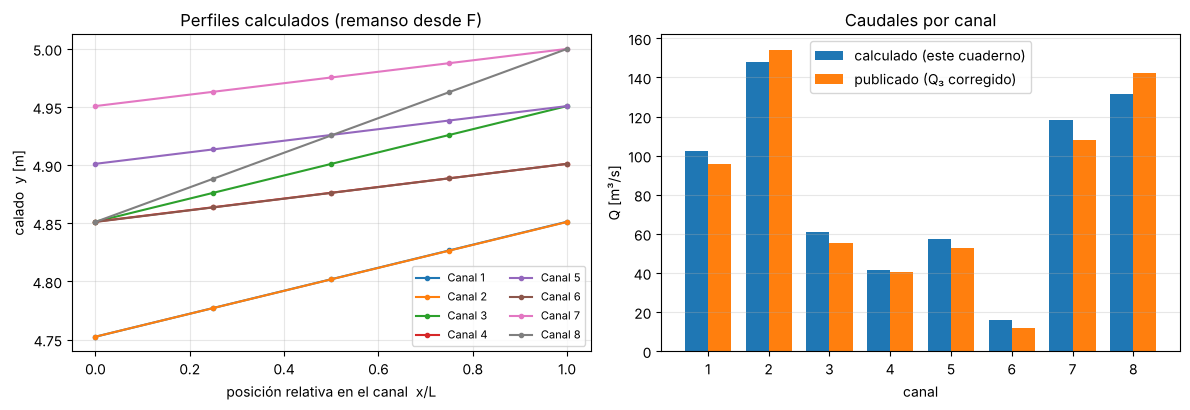

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for i in red.ids:
    yc = X[red.off[i]:red.off[i] + red.N[i] + 1]
    xs = np.arange(red.N[i] + 1)*CANALES[i][4]
    ax[0].plot(xs/CANALES[i][2], yc, marker="o", ms=3, label=f"Canal {i}")
ax[0].set_xlabel("posición relativa en el canal  x/L"); ax[0].set_ylabel("calado  y [m]")
ax[0].set_title("Perfiles calculados (remanso desde F)"); ax[0].legend(ncol=2, fontsize=8); ax[0].grid(alpha=.3)
w = 0.38; ids = np.array(red.ids)
ax[1].bar(ids - w/2, [X[red.iQ[i]] for i in ids], w, label="calculado (este cuaderno)")
ax[1].bar(ids + w/2, [Q_pub[i] for i in ids], w, label="publicado (Q₃ corregido)")
ax[1].set_xlabel("canal"); ax[1].set_ylabel("Q [m³/s]"); ax[1].set_title("Caudales por canal"); ax[1].legend(); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

## 9. Por qué los caudales calculados difieren de los publicados

Los calados coinciden a ~2 mm y P1 muestra que el libro cumple nuestras ecuaciones a nivel de redondeo, pero los caudales difieren varios m³/s. La explicación propuesta es de **condicionamiento**, y se puede comprobar con dos cálculos.

**(a) Fricción muy pequeña frente a la pendiente.** Con calados de unos 4.9 m y velocidades de ~0.5 m/s, $S_f/S_o$ es del orden de 0.02: la superficie libre es casi horizontal y las diferencias de nivel que reparten el caudal entre los dos caminos son de unos pocos milímetros.

**(b) Un solo paso de Newton desde el punto impreso.** Si el libro fuera una raíz exacta, el paso de Newton desde su tabla sería casi nulo. Lo que se observa es lo contrario.

In [13]:
Fp_full, Jp_full = red.F_J(Xpub)
# para (b) se completan las entradas excluidas con la solucion calculada, para tener un punto completo
Xcomp = Xpub.copy()
for (i, j) in excl:
    Xcomp[red.off[i] + j] = X[red.off[i] + j]
d = np.linalg.solve(red.J(Xcomp), -red.F(Xcomp))
dQ = np.array([d[red.iQ[i]] for i in red.ids])
dy = np.concatenate([d[red.off[i]:red.off[i] + red.N[i] + 1] for i in red.ids])

print(f"Residual máx. en el punto impreso (completado): {np.max(np.abs(red.F(Xcomp)))*1000:.2f} mm")
print(f"Paso de Newton desde ese punto: |Δy| máx = {np.max(np.abs(dy))*1000:.2f} mm,  |ΔQ| máx = {np.max(np.abs(dQ)):.2f} m³/s")
print("ΔQ por canal [m³/s]:", np.round(dQ, 2))

Sf_So = [friccion(X[red.off[i] + 2], X[red.iQ[i]], CANALES[i][3], CANALES[i][5])[0]/CANALES[i][6] for i in red.ids]
print("Sf/So por canal    :", np.round(Sf_So, 3))
sv = np.linalg.svd(red.J(X), compute_uv=False)
print(f"Número de condición del Jacobiano en la solución: {sv[0]/sv[-1]:.1e}")

Residual máx. en el punto impreso (completado): 1.20 mm
Paso de Newton desde ese punto: |Δy| máx = 1.92 mm,  |ΔQ| máx = 10.60 m³/s
ΔQ por canal [m³/s]: [  6.55  -6.55   5.7    0.85   4.9    4.05  10.6  -10.6 ]
Sf/So por canal    : [0.019 0.023 0.011 0.007 0.011 0.001 0.026 0.013]
Número de condición del Jacobiano en la solución: 5.2e+05


In [14]:
for fac in (1.0, 1.486, 2.0):
    can_f = {i: (a, b_, L, bb, dx, n_*fac, So) for i, (a, b_, L, bb, dx, n_, So) in CANALES.items()}
    r_f = Red(canales=can_f)
    x_f, t_f, ok_f = newton_amortiguado(r_f.F, r_f.J, X, tol=1e-12)
    print(f"n × {fac:5.3f}: convergió={ok_f}  Q = {np.round([x_f[r_f.iQ[i]] for i in r_f.ids], 1)}")
print("publicado     :        Q =", np.round([Q_pub[i] for i in red.ids], 1))

n × 1.000: convergió=True  Q = [102.3 147.7  60.7  41.5  57.5  16.  118.3 131.7]
n × 1.486: convergió=True  Q = [102.7 147.3  59.1  43.6  58.9  15.3 118.  132. ]
n × 2.000: convergió=True  Q = [102.8 147.2  58.7  44.   59.2  15.1 117.9 132.1]
publicado     :        Q = [ 95.7 154.3  55.1  40.7  52.7  12.  107.8 142.2]


**Interpretación (hipótesis respaldada por estos números, no demostrada).** Un residual de ~1 mm, que es la resolución de la tabla, basta para que un paso de Newton cambie los caudales en varios m³/s mientras los calados casi no se mueven. Es decir, **los calados impresos a milímetro no fijan los caudales** en esta red. Nuestro resultado es la raíz exacta del sistema planteado (residual ≈ 1e-12, 40 de 40 arranques al mismo punto, Runge–Kutta independiente de acuerdo); el libro reporta una solución compatible con sus calados redondeados.

**Lo que no puedo afirmar.** Si el programa original del libro cumplía su tolerancia (0.0005) y terminó en un punto distinto de nuestra raíz, o si el libro usó una forma ligeramente distinta de la fricción, **no lo sé**: no tengo el código del Apéndice D-4 ni más cifras. Descarto, eso sí, una diferencia de unidades de Manning: la celda siguiente muestra que cambiar n por un factor (1.486 o 2) casi no altera el reparto.

**Consecuencia para el trabajo.** Este caso publicado verifica que el resolvedor y el ensamblaje (energía, continuidad, nivel común en unión, condiciones de borde) son correctos y reproducen la tabla del libro dentro de su precisión impresa. **No** sirve para validar la distribución de caudales con un error de unidades porcentuales. Para eso hacen falta datos medidos (Fase IV) o el modelo 2D.

**Dato para la Fase III.** Una red tan poco sensible a la fricción es un caso de *alta* incertidumbre en la partición de caudales ante errores de rugosidad o de nivel: es justo el tipo de resultado que el análisis de sensibilidad debe cuantificar con elasticidades.

## 10. Notas y límites

* **Uniones sin carga de velocidad.** El libro muestra calados iguales en cada nodo, por lo que aquí se usa nivel común (Ec. 6-67 en su forma entre paréntesis). Se probó añadir carga de velocidad con $k=0$ y $k=0.2$ partiendo de la solución anterior: el Newton **no convergió** porque el caudal del canal 6 (D→C, el menor) tiende a 0 y el código exige $Q>0$. Chaudhry trata el flujo inverso con la forma $Q|Q|$; **no lo implementé**. Es una limitación conocida para pasar a Formulación II con pérdida local en redes donde un ramal pueda invertir el sentido.
* **Régimen subcrítico solamente**, como en el libro (§6-8).
* **Datos.** Transcritos a mano de la Tabla 6-3 y Tabla 6-4; revisar contra el original antes de citar cifras.
* **Reproducibilidad.** Semilla fija `SEMILLA = 20261017`; versiones impresas en la sección 1.

## 11. Referencias

* Chaudhry, M. H. (2008). *Open-Channel Flow* (2.ª ed.). Springer. §6-8, Ejemplo 6-3, Tablas 6-3 y 6-4, Fig. 6-13, Ecs. 6-58 a 6-67.